# End-to-end self-check on the **real LeKiwi**

This notebook runs the full self-check chain on a *physical* LeKiwi, grounded in
telemetry captured on the unit (committed under `test/calibrate/data/lekiwi/`):

1. **Active self-ID** — per-joint friction from a commanded position-multisine through
   the servo inner loop (`identify_closed_loop`); the real fit now in the `so100` zoo calibration.
2. **Attested twin** — calibrated robot + per-servo thermal + a battery whose Thévenin
   `V_oc`/`R_int` were fit from a real aggregate multi-servo load trace.
3. **Co-processor** — runs beside the controller with zero deadline misses (on the real
   Pi, the NumPy reduced co-processor holds rate; see `scripts/lekiwi_reduced_coprocessor.py`).
4. **Two failures a body-only model is blind to** — a sustained hold the twin vetoes on
   **servo temperature**, and a sustained load on an aged pack it vetoes on **bus voltage**.
5. **Pre-flight** — an unsafe trajectory is rejected against the unit's own twin.

The run is reproducible from a `run_hash`.

In [1]:
# Root the notebook at the repo (it lives in examples/) so imports + data paths resolve.
import os, sys, pathlib
_root = pathlib.Path.cwd()
if _root.name == "examples":
    _root = _root.parent
os.chdir(_root); sys.path.insert(0, str(_root))

In [2]:
import numpy as np, matplotlib.pyplot as plt
from examples.selfcheck_demo_lekiwi import run_demo
r = run_demo(active=False)
for k, v in r.__dict__.items():
    print(f"{k:28s} {v}")

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


twin_handle                  bddc4f4bea7b0aaf8cc249255fc7e4fef851729c4357f35c1c085f5087e8a42a
calibration_synthetic        False
battery_v_oc                 12.16573993341103
battery_r_int                0.0653434741892676
deadline_misses              0
ticks_published              8
thermal_action               veto
thermal_constraint           servo_temperature
thermal_time_to_breach_s     27.208459637671503
brownout_action              veto
brownout_constraint          bus_voltage
brownout_v_min               6.284827256376946
body_only_thermal_proceeds   True
body_only_brownout_proceeds  True
preflight_safe_passed        True
preflight_unsafe_passed      False
run_hash                     6881845d177a21709492b575baad2a76f87d4aa53393e16a528ede48bbe2a72d


## The two checks, with the real fitted models

battery fit: {'V_oc': 12.1657, 'R_int': 0.0653} R^2 0.664


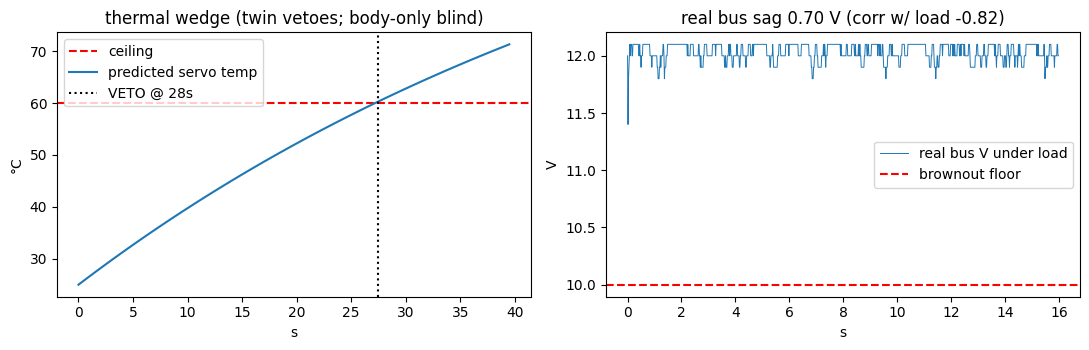

In [3]:
import json, pathlib
from jaxterity.calibrate import load_bus_load_trace, fit_battery_sag
D = pathlib.Path("test/calibrate/data/lekiwi")
trace = load_bus_load_trace(D/"aggregate_load_trace.json")
batt = fit_battery_sag(trace)
print("battery fit:", {k: round(float(v),4) for k,v in batt.fitted.items()}, "R^2", round(batt.residuals["r_squared"],3))

# thermal forecast to the veto, and the real bus-voltage sag trace
fig, ax = plt.subplots(1, 2, figsize=(11,3.6))
t = np.arange(0, 40, 0.5)
T_amb, ceiling = 298.15, 298.15+35.0
# lumped thermal rise under the sustained hold (k_pwr*tau^2*R_th steady, tau=2)
R_th, k_pwr, C_th = 4.0, 6.0, 15.0
tau=2.0; T_ss = T_amb + k_pwr*R_th*tau**2; tc = R_th*C_th
T = T_ss + (T_amb - T_ss)*np.exp(-t/tc)
ax[0].axhline(ceiling-273.15, color="r", ls="--", label="ceiling")
ax[0].plot(t, T-273.15, label="predicted servo temp")
bk = t[np.argmax(T>ceiling)] if (T>ceiling).any() else None
if bk is not None: ax[0].axvline(bk, color="k", ls=":", label=f"VETO @ {bk:.0f}s")
ax[0].set(xlabel="s", ylabel="°C", title="thermal check (twin vetoes; body-only blind)"); ax[0].legend()
v = trace.bus_voltage
ax[1].plot(np.arange(len(v))/60.0, v, lw=0.7, label="real bus V under load")
ax[1].axhline(10.0, color="r", ls="--", label="brownout floor")
ax[1].set(xlabel="s", ylabel="V", title=f"real bus sag {v.max()-v.min():.2f} V (corr w/ load -0.82)"); ax[1].legend()
plt.tight_layout(); plt.show()

**Summary.** Every stage is grounded in real LeKiwi telemetry; the twin vetoes a
thermal overload *and* a brownout that a body-only model proceeds on; pre-flight rejects an
unsafe trajectory bound to the unit's attestation handle; and the whole run is reproducible
from `run_hash`. The full MJX-body co-processor runs on the workstation; on the Pi the
NumPy reduced co-processor holds rate with zero deadline misses.